In [7]:
 import pandas as pd
 from sklearn.model_selection import train_test_split
 from sklearn.feature_extraction.text import TfidfVectorizer
 from sklearn.svm import SVC
 from sklearn.metrics import accuracy_score, precision_score, recall_score,  f1_score, confusion_matrix
 import matplotlib.pyplot as plt
 import seaborn as sns

In [9]:
data = pd.read_csv("spam.csv", encoding='latin-1')
data = data[['v1', 'v2']]
data.columns = ['label', 'text']
print(data.head())


  label                                               text
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [11]:
data['label'] = data['label'].map({'ham': 0, 'spam': 1})
X = data['text']
y = data['label']
vectorizer = TfidfVectorizer(stop_words='english')
X_tfidf = vectorizer.fit_transform(X)
print("Shape of TF-IDF matrix:", X_tfidf.shape)

Shape of TF-IDF matrix: (5572, 8404)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.2, random_state=42 )

svm_model = SVC(kernel='linear')
svm_model.fit(X_train, y_train)

y_pred = svm_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", conf_matrix)
print(f"\nAccuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

Confusion Matrix:
 [[961   4]
 [ 24 126]]

Accuracy: 0.9749
Precision: 0.9692
Recall: 0.8400
F1 Score: 0.9000


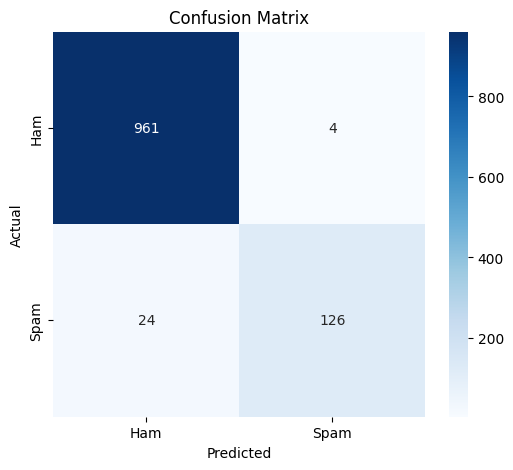

In [15]:
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()
